## Notebook 03 — Temas sem rótulo e recomendações para o negócio

In [1]:
# [C03.01]
# Bibliotecas, base e decisões dos notebooks 01 e 02
import pandas as pd, numpy as np, matplotlib.pyplot as plt, re, unicodedata, itertools
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
SEED = 42

URL = "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv"
df = pd.read_csv(URL, low_memory=False)

# decisões do notebook 01
base = df.dropna(subset=["review_text", "recommend_to_a_friend"]).copy()
base["classe"] = base["recommend_to_a_friend"]
print("Avaliações com texto e recomendação:", len(base))

# decisão do notebook 02: sem textos duplicados
base = base.drop_duplicates(subset="review_text")
print("Depois de remover textos duplicados:", len(base))
print((base["classe"].value_counts(normalize=True) * 100).round(1))
print("Sem categoria de nível 1:", base["site_category_lv1"].isna().sum())

Avaliações com texto e recomendação: 129080
Depois de remover textos duplicados: 126721
classe
Yes    74.1
No     25.9
Name: proportion, dtype: float64
Sem categoria de nível 1: 6


Tal como no notebook 02, a base volta a ser carregada a partir do repositório oficial, pela URL raw, para o notebook correr sozinho do zero. Aplicámos as mesmas decisões dos notebooks 01 e 02. Retirámos as avaliações sem texto e sem recomendação, usámos "recommend_to_a_friend" como rótulo e removemos os textos duplicados. Ficam 126.721 avaliações, com 74,1% de "Yes" e 25,9% de "No".

Decisão sobre a amostra: Neste notebook usamos a base inteira e não a amostra de 40.000 do notebook 02. No notebook 02 a amostra servia para os modelos correrem depressa enquanto desenvolvíamos, como pede o enunciado. Aqui não há treino nem teste, porque os temas não têm rótulo para acertar. O NMF corre em poucos segundos mesmo com a base toda. Usar a base inteira dá mais avaliações em cada recorte, sobretudo nas categorias, e números mais fiáveis para as recomendações. As 6 avaliações sem categoria ficam fora só do recorte por categoria.

## Secção 3.5: Temas sem rótulo

## Preparação do texto para os temas

In [2]:
# [C03.02]
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

def vocabulario(textos):
    return len(set(palavra for texto in textos for palavra in texto.split()))

def sem_acentos(texto):
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))

URL_REGEX = r"https?://\S+"
ESTICADA_REGEX = r"([a-zà-ÿ])\1{2,}"

# o mesmo funil do notebook 02, pela mesma ordem, mas sem stemming
etapas = {"original": base["review_text"]}
etapas["minúsculas"] = etapas["original"].str.lower()
etapas["sem URL"] = etapas["minúsculas"].str.replace(URL_REGEX, " ", regex=True)
etapas["só letras"] = etapas["sem URL"].str.replace(r"[^a-zà-ÿ\s]", " ", regex=True)
etapas["alongamento colapsado"] = etapas["só letras"].str.replace(ESTICADA_REGEX, r"\1", regex=True)
etapas["sem acentos"] = etapas["alongamento colapsado"].apply(sem_acentos)

# stop words: a lista do NLTK, agora COM a negação, e palavras de função informais
STOP = {sem_acentos(p) for p in stopwords.words("portuguese")}
INFORMAIS = {"pra", "pro", "pras", "pros", "vc", "vcs", "q", "pq", "tb", "tbm", "ta", "to", "la", "ai", "entao", "pois", "vou"}
STOP_TEMAS = STOP | INFORMAIS
etapas["sem stop words"] = etapas["sem acentos"].str.split().apply(lambda ts: " ".join(t for t in ts if t not in STOP_TEMAS))

anterior = None
for nome, t in etapas.items():
    v = vocabulario(t)
    print(nome, ", vocabulário", v, ", formas colapsadas", "" if anterior is None else anterior - v)
    anterior = v

# quanto pesam a negação e as palavras informais
palavras = etapas["sem acentos"].str.split()
for p in ["nao", "pra", "pois", "vou"]:
    print("Avaliações com '" + p + "' (%):", round(palavras.apply(lambda ts: p in ts).mean() * 100, 1))

base["texto_tema"] = etapas["sem stop words"]
base["texto_sem_acentos"] = etapas["sem acentos"]   # com stop words, para procurar frases como "nao recebi"

# variedade = palavras distintas / palavras; perto de 0 quando o cliente repete a mesma frase
palavras_cruas = base["review_text"].str.lower().str.findall(r"[a-zà-ÿ]+")
base["variedade"] = palavras_cruas.apply(lambda ts: len(set(ts)) / len(ts) if ts else 0)
for i in range(3):
    print()
    print("Antes :", base["review_text"].iloc[i][:150])
    print("Depois:", base["texto_tema"].iloc[i][:150])

original , vocabulário 139116 , formas colapsadas 


minúsculas , vocabulário 117359 , formas colapsadas 21757


sem URL , vocabulário 117304 , formas colapsadas 55


só letras , vocabulário 47823 , formas colapsadas 69481


alongamento colapsado , vocabulário 46769 , formas colapsadas 1054


sem acentos , vocabulário 44130 , formas colapsadas 2639
sem stop words , vocabulário 43941 , formas colapsadas 189


Avaliações com 'nao' (%): 32.7
Avaliações com 'pra' (%): 5.8
Avaliações com 'pois' (%): 5.2
Avaliações com 'vou' (%): 2.0



Antes : Estou contente com a compra entrega rápida o único problema com as Americanas é se houver troca ou devolução do produto o consumidor tem problemas com
Depois: contente compra entrega rapida unico problema americanas troca devolucao produto consumidor problemas espera

Antes : Por apenas R$1994.20,eu consegui comprar esse lindo copo de acrílico.
Depois: apenas r consegui comprar lindo copo acrilico

Antes : SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANELAS ELÉTRICAS.  COSTUMO USAR OUTRA PANELA PARA COZIMENTO DE ARROZ (JAPONESA), MAS LEVA MUITO TEMPO,  +/- 
Depois: supera agilidade praticidade outras panelas eletricas costumo usar outra panela cozimento arroz japonesa leva tempo minutos nessa panela rapido exatam


Usámos o mesmo funil do notebook 02, pela mesma ordem: minúsculas, remoção de URL, só letras, alongamento colapsado e remoção dos acentos. Para os temas mudámos três decisões, porque a tarefa é outra. No classificador o que importa é acertar a classe. Nos temas o que importa é conseguir ler e dar nome a cada grupo de palavras.

Sem stemming: No notebook 02 o RSLP deixava radicais como "livr", "necess" ou "entreg". Para o classificador isso não faz mal, mas um tema feito de radicais é difícil de ler e de nomear. Por isso aqui ficamos com as palavras inteiras. O custo aparece no vocabulário, que fica com 43.941 formas em vez das 11.982 do notebook 02.

A negação sai: No classificador mantivemos "não" e "nem", porque invertem o sentido da frase. Nos temas não queremos o sentido da frase, queremos o assunto. "Nao" aparece em 32,7% das avaliações e entraria no topo de quase todos os temas negativos sem dizer de que assunto se trata. Por isso usamos a lista completa do NLTK.

Palavras de função informais: Juntámos à lista 17 palavras de função que o NLTK não tem, como "pra", "pro", "vc", "pq" e "pois". São palavras da escrita informal que não dizem nada sobre o assunto, como "pra", que aparece em 5,8% das avaliações.

O alongamento colapsado junta 1.054 formas e os acentos juntam mais 2.639. Removemos também as palavras com menos de 3 letras, como nas aulas, e as que aparecem em menos de 5 avaliações (min_df=5).

## Recorte 1, por polaridade: escolha do k

In [3]:
# [C03.03]
def ajustar_nmf(textos, k):
    # TF-IDF e NMF como na aula de 11/09
    vetorizador = TfidfVectorizer(min_df=5, token_pattern=r"(?u)\b[a-z]{3,}\b")
    M = vetorizador.fit_transform(textos)
    modelo = NMF(n_components=k, random_state=SEED, init="nndsvda", max_iter=400)
    W = modelo.fit_transform(M)
    termos = np.array(vetorizador.get_feature_names_out())
    topo = [list(termos[np.argsort(c)[-10:]][::-1]) for c in modelo.components_]
    return vetorizador, modelo, W, topo

def pares_repetidos(topo):
    # pares de temas que partilham 3 ou mais dos seus 10 termos principais
    return sum(len(set(a) & set(b)) >= 3 for a, b in itertools.combinations(topo, 2))

negativas = base[base["classe"] == "No"]
positivas = base[base["classe"] == "Yes"]
print("Avaliações negativas ('No'):", len(negativas), ", positivas ('Yes'):", len(positivas))

for nome, grupo, mostrar in [("NEGATIVAS", negativas, (6, 8, 10)), ("POSITIVAS", positivas, (4, 6, 8))]:
    print()
    print("=====", nome)
    for k in [4, 6, 8, 10, 12]:
        _, modelo, _, topo = ajustar_nmf(grupo["texto_tema"], k)
        print(f"k={k}: erro de reconstrução {modelo.reconstruction_err_:.1f}, pares de temas repetidos {pares_repetidos(topo)}")
        if k in mostrar:
            for i, t in enumerate(topo, start=1):
                print(f"     tema {i}:", ", ".join(t[:8]))

Avaliações negativas ('No'): 32862 , positivas ('Yes'): 93859

===== NEGATIVAS


k=4: erro de reconstrução 177.4, pares de temas repetidos 1


k=6: erro de reconstrução 176.5, pares de temas repetidos 1
     tema 1: qualidade, produto, recomendo, pessima, ruim, gostei, bem, bom
     tema 2: recebi, produto, ainda, hoje, momento, agora, paguei, comprei
     tema 3: dia, entrega, americanas, comprei, nada, compra, dias, prazo
     tema 4: ainda, chegou, mes, produto, prazo, entrega, chegar, faz
     tema 5: veio, defeito, troca, produto, devolucao, faltando, quebrado, contato
     tema 6: avaliar, posso, entregue, produto, algo, porque, receber, coisa


k=8: erro de reconstrução 175.8, pares de temas repetidos 0
     tema 1: produto, entregue, original, gostaria, devolucao, dinheiro, quero, saber
     tema 2: recebi, ainda, produto, hoje, agora, paguei, momento, comprei
     tema 3: entrega, dia, prazo, hoje, data, previsao, dias, passou
     tema 4: ainda, chegou, mes, faz, chegar, pedido, quase, avaliacao
     tema 5: veio, defeito, troca, faltando, quebrado, devolucao, pedi, solicitei
     tema 6: avaliar, posso, algo, porque, receber, coisa, infelizmente, portanto
     tema 7: americanas, comprei, nada, compra, loja, agora, site, dias
     tema 8: qualidade, pessima, recomendo, ruim, material, bem, gostei, uso


k=10: erro de reconstrução 175.2, pares de temas repetidos 2
     tema 1: produto, quero, dinheiro, original, devolucao, gostaria, saber, bom
     tema 2: recebi, ainda, mes, hoje, agora, paguei, comprei, mercadoria
     tema 3: entrega, prazo, dias, passou, demora, data, atraso, rapida
     tema 4: chegou, ainda, mes, chegar, casa, quebrado, prazo, antes
     tema 5: veio, defeito, troca, faltando, quebrado, devolucao, solicitei, pedi
     tema 6: avaliar, posso, ainda, algo, porque, receber, coisa, produto
     tema 7: americanas, comprei, compra, nada, loja, site, agora, dias
     tema 8: qualidade, pessima, recomendo, ruim, material, bem, gostei, uso
     tema 9: dia, hoje, comprei, agora, previsao, desde, nada, chegar
     tema 10: entregue, pedido, ainda, consta, avaliacao, momento, sido, site


k=12: erro de reconstrução 174.6, pares de temas repetidos 1

===== POSITIVAS


k=4: erro de reconstrução 295.2, pares de temas repetidos 3
     tema 1: bom, produto, recomendo, otimo, expectativas, gostei, atendeu, custo
     tema 2: prazo, antes, chegou, bem, produto, previsto, dentro, entregue
     tema 3: entrega, rapida, super, produto, recomendo, americanas, otimo, parabens
     tema 4: qualidade, excelente, otima, produto, boa, recomendo, todos, imagem


k=6: erro de reconstrução 292.5, pares de temas repetidos 5
     tema 1: bom, produto, recomendo, preco, gostei, aparelho, rapido, celular
     tema 2: prazo, antes, chegou, bem, produto, previsto, dentro, entregue
     tema 3: entrega, rapida, super, americanas, produto, parabens, recomendo, otimo
     tema 4: qualidade, excelente, produto, recomendo, otima, boa, gostei, todos
     tema 5: otimo, custo, beneficio, produto, aparelho, preco, celular, vale
     tema 6: expectativas, atendeu, superou, todas, produto, atende, necessidades, gostei


k=8: erro de reconstrução 290.1, pares de temas repetidos 7
     tema 1: bom, produto, preco, aparelho, celular, dia, facil, bonito
     tema 2: prazo, antes, chegou, bem, previsto, produto, dentro, entregue
     tema 3: entrega, rapida, super, americanas, parabens, produto, sempre, lojas
     tema 4: qualidade, otima, boa, produto, preco, imagem, bonito, material
     tema 5: otimo, custo, beneficio, aparelho, preco, vale, celular, produto
     tema 6: expectativas, atendeu, superou, todas, produto, atende, necessidades, bem
     tema 7: recomendo, gostei, super, produto, todos, rapido, pratico, otimo
     tema 8: excelente, produto, qualidade, facil, compra, atendimento, imagem, preco


k=10: erro de reconstrução 288.0, pares de temas repetidos 4


k=12: erro de reconstrução 286.2, pares de temas repetidos 7


O primeiro recorte separa as avaliações pela nossa classe, 32.862 negativas ("No") e 93.859 positivas ("Yes"), e procura temas em cada grupo. O NMF não sabe quantos assuntos existem, por isso o k é escolha nossa. Testámos cinco valores, de 4 a 12, nos dois grupos. Usámos TF-IDF com min_df=5, NMF com init="nndsvda" e a semente 42.

Para cada k medimos duas coisas. A primeira é o erro de reconstrução, que mede quanto se perde ao resumir a matriz em k temas. A segunda são os pares de temas repetidos, ou seja, pares de temas que partilham 3 ou mais dos seus 10 termos principais. Um par repetido é sinal de que o mesmo assunto foi partido em dois.

O erro de reconstrução não decide sozinho. Desce sempre que o k sobe, mas devagar e sem cotovelo. Nas negativas passa de 177,4 com k=4 para 174,6 com k=12. Decidimos olhando para os pares repetidos e lendo os termos.

Negativas, k=8: É o único valor sem nenhum par de temas repetido. Com k=6 a reclamação contra a loja e o atraso na entrega ficam juntos num só tema ("dia, entrega, americanas, comprei, nada"). Com k=8 separam-se e aparecem dois temas novos, um sobre a loja e o site e outro sobre o dinheiro de volta. Com k=10 o "ainda não chegou" parte-se em temas quase iguais, como o 4 e o 9, e aparecem 2 pares repetidos.

Positivas, k=6: Aqui os pares repetidos são sempre mais, porque os elogios usam as mesmas palavras ("produto", "recomendo", "otimo"). Com k=4 o custo-benefício e o "atendeu as expectativas" ficam misturados no elogio genérico do tema 1. Com k=6 os dois ficam separados. Com k=8 os dois temas novos são o 7 ("recomendo, gostei, super") e o 8 ("excelente, produto, qualidade"), que são mais elogio genérico sem assunto, e os pares repetidos sobem de 5 para 7. O k=6 é o maior k em que cada tema novo traz um assunto novo.

## Recorte 1: os temas das avaliações negativas (k = 8)

In [4]:
# [C03.04]
def mostrar_temas(grupo, k, nomes=None, minimo_palavras=6):
    vetorizador, modelo, W, topo = ajustar_nmf(grupo["texto_tema"], k)
    dominante = pd.Series(np.where(W.max(axis=1) > 0, W.argmax(axis=1) + 1, 0), index=grupo.index)
    n_palavras = grupo["review_text"].str.split().str.len().values
    variedade = grupo["variedade"].values
    for i, t in enumerate(topo):
        tema = i + 1
        titulo = nomes[tema] if nomes else ""
        print(f"=== tema {tema} {titulo} | {(dominante == tema).sum()} avaliações ({(dominante == tema).mean() * 100:.1f}%)")
        print("    termos:", ", ".join(t))
        # as três avaliações com mais peso no tema, entre as que têm o tema como principal,
        # pelo menos 6 palavras e pouca repetição (ver "Temas-artefato")
        candidata = (dominante.values == tema) & (n_palavras >= minimo_palavras) & (variedade >= 0.6)
        peso = np.where(candidata, W[:, i], -1)
        for j in np.argsort(peso)[-3:][::-1]:
            print("    -", grupo["review_text"].iloc[j][:170].replace("\n", " "))
    return dominante, W, topo

tema_negativas, W_neg, topo_neg = mostrar_temas(negativas, 8)

=== tema 1  | 3293 avaliações (10.0%)
    termos: produto, entregue, original, gostaria, devolucao, dinheiro, quero, saber, momento, avaliacao
    - ... Produto para tolos, inocentes e iludidos..............................................................................................................................
    - Meu produto não foi entregue. Não recebi meu produto.
    - O produto não foi entregue... .........................................
=== tema 2  | 2854 avaliações (8.7%)
    termos: recebi, ainda, produto, hoje, agora, paguei, momento, comprei, mercadoria, resposta
    - nao recebi o produto.              ????????????????????????????? nao recebbiiiiiiii nao recebi
    - Como vou avaliacar um produto que nao recebi??..........................................................................
    - Não recebi o produto!!! O praz já estorou e ainda não recebi o meu produto!
=== tema 3  | 3340 avaliações (10.2%)
    termos: entrega, dia, prazo, hoje, data, previsao, dias, 

Para cada tema mostramos os 10 termos com mais peso, quantas avaliações têm aquele tema como principal e três avaliações reais. As três avaliações são as que têm mais peso no tema. Escolhemos só avaliações com pelo menos 6 palavras e sem texto repetido para encher, que explicamos nos temas-artefato. Lemos os termos e as avaliações e demos um nome a cada tema.

| Tema | Nome | Avaliações | Exemplo |
|---|---|---|---|
| 1 | Não conseguimos nomear: tema misto | 3.293 (10,0%) | "Meu produto não foi entregue. Não recebi meu produto." |
| 2 | Paguei e não recebi | 2.854 (8,7%) | "Não recebi o produto!!! O praz já estorou e ainda não recebi o meu produto!" |
| 3 | Prazo de entrega ultrapassado | 3.340 (10,2%) | "A entrega está muito atrasada. Depois que fiz a compra, passou o prazo de entrega [...]" |
| 4 | Ainda não chegou | 1.850 (5,6%) | "Ainda não chegou, quase 1 mês após a compra, o produto ainda nao chegou." |
| 5 | Defeito, peça faltando, troca | 4.287 (13,0%) | "Recebi o produto, mas ele veio com defeito" |
| 6 | Não posso avaliar o que não recebi | 1.140 (3,5%) | "Não posso avaliar, pois não recebi o mesmo. Não conheci o produto." |
| 7 | Queixa contra a loja (Americanas ou parceiro) | 7.696 (23,4%) | "Não sei se é problema da Americanas ou da loja [...]" |
| 8 | Má qualidade | 8.367 (25,5%) | "O material é de péssima qualidade, na foto parecia um material bom [...]" |

Tema 1, sem nome: Os termos misturam "entregue", "original", "devolucao" e "dinheiro". As três avaliações de topo falam de produto não entregue, mas ao ler outras avaliações do tema encontrámos de tudo um pouco: produto não original, peças em falta, devoluções à espera e informação que falta na página. A palavra que junta o tema é "produto" e não um assunto. Declaramos que não conseguimos dar-lhe nome, por isso não entra no relatório como assunto.

Cinco dos oito temas são sobre a entrega e não sobre o produto: os temas 2, 3, 4 e 6, e parte do 1. O tema 6 é o mais curioso. São clientes a quem foi pedida uma avaliação de um produto que ainda não chegou, e que respondem com 1 estrela. Voltamos a este tema na secção 3.6.

## Recorte 1: os temas das avaliações positivas (k = 6)

In [5]:
# [C03.05]
tema_positivas, W_pos, topo_pos = mostrar_temas(positivas, 6)

=== tema 1  | 15047 avaliações (16.0%)
    termos: bom, produto, recomendo, preco, gostei, aparelho, rapido, celular, facil, bem
    - muito bom bom de mais muiiiiito bom    recomendo esse produto
    - Muito bom.   .                                                 .                                                               .     .                                    
    - Se é Bayer, é bom .............................................................
=== tema 2  | 15482 avaliações (16.5%)
    termos: prazo, antes, chegou, bem, produto, previsto, dentro, entregue, entrega, perfeito
    - Muito bom chegou antes do prazo kkkkkkkkkkkkllkkkkkk kkkkkkk
    - chegou antes do prazo ; Muito bom................................................
    - O produto é  muito bom  , chegou no antes do prazo .
=== tema 3  | 12466 avaliações (13.3%)
    termos: entrega, rapida, super, americanas, produto, parabens, recomendo, otimo, sempre, lojas
    - O produto é muito bom e a entrega foi super rápid

| Tema | Nome | Avaliações | Exemplo |
|---|---|---|---|
| 1 | Elogio genérico ("muito bom") — sem assunto | 15.047 (16,0%) | "muito bom bom de mais muiiiiito bom recomendo esse produto" |
| 2 | Chegou antes do prazo | 15.482 (16,5%) | "O produto é muito bom, chegou no antes do prazo." |
| 3 | Entrega rápida | 12.466 (13,3%) | "O produto é excelente e a entrega foi super rápida." |
| 4 | Elogio genérico à qualidade — sem assunto | 30.760 (32,8%) | "Excelente produto, recomendo muito, produto de ótima qualidade." |
| 5 | Custo-benefício | 13.417 (14,3%) | "Otimo produto, otimo custo x beneficio. recomendo este produto" |
| 6 | Atendeu às expectativas | 6.450 (6,9%) | "É UM PRODUTO QUE ATENDEU ÀS EXPECTATIVAS. POR ISSO, O RECOMENDO." |

Os elogios são muito mais repetitivos do que as reclamações. Quem não recomenda explica porquê. Quem recomenda escreve quase sempre uma de poucas frases feitas, e as três avaliações de cada tema são quase iguais entre si.

Os temas 1 e 4 juntam quase metade dos elogios (48,8%), mas não têm assunto. Dizem que o produto é bom ou de qualidade sem dizer em quê. Damos-lhes um nome para os podermos contar, mas declaramos que não são assuntos e não entram no relatório como tal. Os assuntos reais dos elogios são três: a entrega (temas 2 e 3, 29,8% dos elogios), o preço (tema 5) e o produto cumprir o que prometia (tema 6). A entrega aparece dos dois lados. É o assunto principal das reclamações e também dos elogios.

## Recorte 2, por categoria de produto

In [6]:
# [C03.06]
# as três categorias com mais avaliações
CATEGORIAS = base["site_category_lv1"].value_counts().index[:3].tolist()
for c in CATEGORIAS:
    grupo = base[base["site_category_lv1"] == c]
    print(c, ":", len(grupo), "avaliações,", round((grupo["classe"] == "No").mean() * 100, 1), "% não recomendam")

# primeiro teste: todas as avaliações da maior categoria
print()
print("=====", CATEGORIAS[0], ", todas as avaliações, k=6")
_, _, _, topo = ajustar_nmf(base.loc[base["site_category_lv1"] == CATEGORIAS[0], "texto_tema"], 6)
for i, t in enumerate(topo, start=1):
    print(f"     tema {i}:", ", ".join(t[:8]))

Celulares e Smartphones : 20095 avaliações, 19.3 % não recomendam
Eletroportáteis : 11447 avaliações, 17.4 % não recomendam
Beleza e Perfumaria : 8662 avaliações, 25.4 % não recomendam

===== Celulares e Smartphones , todas as avaliações, k=6


     tema 1: prazo, antes, chegou, produto, previsto, bem, entrega, dentro
     tema 2: celular, rapido, camera, bateria, aparelho, boa, otima, excelente
     tema 3: entrega, rapida, super, produto, excelente, recomendo, americanas, parabens
     tema 4: custo, beneficio, otimo, aparelho, excelente, relacao, melhor, desempenho
     tema 5: expectativas, atendeu, superou, todas, atende, produto, necessidades, excelente
     tema 6: bom, recomendo, produto, gostei, todos, preco, aparelho, necessidades


O segundo recorte é por categoria de produto (site_category_lv1). Escolhemos as três categorias com mais avaliações: Celulares e Smartphones (20.095), Eletroportáteis (11.447) e Beleza e Perfumaria (8.662).

O primeiro teste foi com todas as avaliações da maior categoria. Saíram os mesmos temas do recorte positivo: "chegou antes do prazo", "entrega rápida", "custo-benefício" e "atendeu as expectativas". Só um tema era da categoria ("celular, rapido, camera, bateria"). Como 80,7% das avaliações dos celulares recomendam o produto, os elogios genéricos dominam a matriz e escondem o que é próprio da categoria. Por isso fazemos o recorte por categoria só com as avaliações negativas. É também o recorte mais útil para a secção 3.6, porque mostra de que se queixam os clientes de cada categoria.

In [7]:
# [C03.07]
# escolha do k em cada categoria, só com as avaliações negativas
for c in CATEGORIAS:
    grupo = negativas[negativas["site_category_lv1"] == c]
    print()
    print("=====", c, ",", len(grupo), "avaliações negativas")
    for k in [4, 6, 8]:
        _, modelo, _, topo = ajustar_nmf(grupo["texto_tema"], k)
        print(f"k={k}: erro de reconstrução {modelo.reconstruction_err_:.1f}, pares de temas repetidos {pares_repetidos(topo)}")
        for i, t in enumerate(topo, start=1):
            print(f"     tema {i}:", ", ".join(t[:8]))


===== Celulares e Smartphones , 3873 avaliações negativas
k=4: erro de reconstrução 60.4, pares de temas repetidos 0
     tema 1: recebi, ainda, produto, avaliar, posso, chegou, mes, momento
     tema 2: celular, aparelho, bateria, tela, uso, bom, problema, camera
     tema 3: dia, entrega, americanas, prazo, dias, comprei, compra, produto
     tema 4: veio, defeito, produto, qualidade, original, troca, carregador, pessima


k=6: erro de reconstrução 60.0, pares de temas repetidos 0
     tema 1: recebi, produto, ainda, avaliar, posso, chegou, mes, momento
     tema 2: aparelho, uso, problema, assistencia, tela, menos, meses, dias
     tema 3: dia, entrega, americanas, prazo, dias, produto, comprei, compra
     tema 4: veio, defeito, produto, troca, qualidade, carregador, pessima, fone
     tema 5: bateria, dura, original, carga, rapido, descarrega, qualidade, recomendo
     tema 6: celular, tela, pelicula, bom, camera, comprei, ruim, funciona


k=8: erro de reconstrução 59.6, pares de temas repetidos 1
     tema 1: recebi, ainda, avaliar, posso, produto, mes, hoje, momento
     tema 2: aparelho, tela, pelicula, camera, bom, trava, bem, ruim
     tema 3: dia, entrega, americanas, prazo, comprei, hoje, compra, nada
     tema 4: veio, defeito, troca, carregador, fone, comprei, ouvido, devolucao
     tema 5: bateria, dura, carga, rapido, descarrega, original, carregar, horas
     tema 6: celular, carregador, funciona, comprei, chip, bom, comprar, fica
     tema 7: produto, chegou, original, qualidade, pessima, gostei, dinheiro, pessimo
     tema 8: uso, dias, menos, funcionar, problema, parou, assistencia, mes

===== Eletroportáteis , 1991 avaliações negativas
k=4: erro de reconstrução 43.3, pares de temas repetidos 0
     tema 1: produto, veio, defeito, americanas, dias, troca, comprei, uso
     tema 2: agua, gelada, sai, gela, natural, purificador, fria, pressao
     tema 3: recebi, ainda, produto, avaliar, posso, entregue, hoj

k=6: erro de reconstrução 43.0, pares de temas repetidos 0
     tema 1: produto, uso, recomendo, bem, comprei, qualidade, bom, fraco
     tema 2: agua, gelada, sai, gela, natural, purificador, fria, pressao
     tema 3: recebi, produto, avaliar, ainda, posso, entregue, entrega, hoje
     tema 4: cafe, cafeteira, fica, quente, filtro, sai, morno, xicara
     tema 5: veio, defeito, troca, produto, americanas, devolucao, contato, pedi
     tema 6: chegou, quebrado, ainda, produto, rapido, tudo, chegar, prazo
k=8: erro de reconstrução 42.7, pares de temas repetidos 0
     tema 1: produto, recomendo, bem, qualidade, bom, fraco, gostei, copo
     tema 2: agua, gelada, sai, gela, natural, purificador, fria, pressao
     tema 3: recebi, avaliar, produto, ainda, posso, entregue, hoje, dia
     tema 4: cafe, cafeteira, quente, fica, filtro, sai, morno, xicara
     tema 5: veio, defeito, troca, produto, pedi, devolucao, aguardo, consegui
     tema 6: chegou, quebrado, ainda, produto, rapido, tudo

k=4: erro de reconstrução 45.5, pares de temas repetidos 0
     tema 1: recebi, produto, ainda, entrega, chegou, avaliar, dia, prazo
     tema 2: perfume, original, cheiro, fixacao, pessima, comprei, americanas, parece
     tema 3: cabelo, esquenta, bem, gostei, escova, alisa, recomendo, chapinha
     tema 4: veio, produto, defeito, outro, comprei, troca, funciona, recomendo
k=6: erro de reconstrução 45.1, pares de temas repetidos 0
     tema 1: recebi, produto, avaliar, ainda, posso, entregue, momento, avaliacao
     tema 2: perfume, original, cheiro, fixacao, pessima, parece, qualidade, dura
     tema 3: cabelo, esquenta, bem, gostei, alisa, recomendo, produto, escova
     tema 4: veio, produto, defeito, outro, troca, funciona, errado, faltando
     tema 5: chegou, entrega, prazo, ainda, dia, dias, produto, hoje
     tema 6: americanas, comprei, site, produto, nada, compra, loja, nunca


k=8: erro de reconstrução 44.8, pares de temas repetidos 3
     tema 1: recebi, produto, ainda, hoje, momento, agora, devolucao, mes
     tema 2: perfume, original, cheiro, fixacao, pessima, parece, qualidade, dura
     tema 3: cabelo, esquenta, bem, gostei, alisa, produto, escova, recomendo
     tema 4: veio, produto, defeito, outro, troca, funciona, errado, faltando
     tema 5: chegou, produto, hoje, mes, prazo, antes, dia, comprei
     tema 6: americanas, comprei, site, nada, compra, lojas, loja, nunca
     tema 7: entrega, ainda, prazo, dias, dia, avaliacao, previsao, atraso
     tema 8: avaliar, posso, entregue, produto, ainda, algo, porque, momento


Testámos k=4, 6 e 8 nas avaliações negativas de cada categoria, com os mesmos dois critérios do recorte por polaridade. Escolhemos k=6 nas três.

Com k=4 junta-se o que é diferente. Nos celulares, a bateria, a tela e a câmera ficam todas no mesmo tema ("celular, aparelho, bateria, tela"). Em Beleza e Perfumaria o atraso e a não entrega ficam juntos. Com k=6 nenhuma das três categorias tem pares de temas repetidos e cada tema tem um assunto. Com k=8 começam as repetições. Beleza e Perfumaria fica com 3 pares repetidos, porque o "não recebi" se parte em três temas (1, 7 e 8), e os celulares ficam com 1. Usar o mesmo k nas três categorias também facilita a comparação entre elas.

In [8]:
# [C03.08]
# k = 6 em cada categoria: termos, tamanho e três avaliações por tema
temas_categoria = {}
for c in CATEGORIAS:
    print()
    print("##########", c)
    grupo = negativas[negativas["site_category_lv1"] == c]
    temas_categoria[c] = mostrar_temas(grupo, 6)


########## Celulares e Smartphones


=== tema 1  | 332 avaliações (8.6%)
    termos: recebi, produto, ainda, avaliar, posso, chegou, mes, momento, receber, avaliacao
    - Não posso avaliar pois ainda não recebi o produto.
    - Não posso avaliar pq ainda não recebi o produto!!!
    - Ainda nem recebi o produto, como vou aproveitar????????
=== tema 2  | 749 avaliações (19.3%)
    termos: aparelho, uso, problema, assistencia, tela, menos, meses, dias, funcionar, parou
    - Comprei o aparelho com menos de 30 dias de uso a tela travou, e continua com o problema, após vim da assistência pois não disponibilizaram um novo aparelho
    - Com menos de 20 dias de uso o aparelho já está apresentando defeito não gostei do aparelho.
    - Aparelho aparentemente bom com relação  a custo  benefício, porém com 3 meses de uso começou  a ter problemas no touch screen, ignorei o problema, com 6 meses o problema 
=== tema 3  | 1087 avaliações (28.1%)
    termos: dia, entrega, americanas, prazo, dias, produto, comprei, compra, nada, hoje
  

=== tema 1  | 208 avaliações (9.5%)
    termos: recebi, produto, avaliar, ainda, posso, entregue, momento, avaliacao, paguei, saber
    - Não tenho como avaliar positivamente pois não recebi o produto.
    - Não tem como avaliar pois paguei e não recebi o produto
    - estou com um enorme problema pois ainda nao recebi o produto
=== tema 2  | 273 avaliações (12.4%)
    termos: perfume, original, cheiro, fixacao, pessima, parece, qualidade, dura, alcool, recomendo
    - O perfume não é original . Uso esse perfume a bastante tempo ,e esse que comprei não tem fixação nenhuma.
    - Perfume de péssima qualidade, sem fixação até mesmo em locais fechados e com ar condicionado o perfume não fixa, não acredito que este produto ''original'' da Ferrari sej
    - O cheiro do perfume é muito bom, mas a fixação na pele é péssima. por não recomendo.
=== tema 3  | 531 avaliações (24.1%)
    termos: cabelo, esquenta, bem, gostei, alisa, recomendo, produto, escova, chapinha, fica
    - Eu gostei mais q

Celulares e Smartphones (3.873 reclamações):

| Tema | Nome | % | Exemplo |
|---|---|---|---|
| 1 | Não recebi / não posso avaliar | 8,6 | "Não posso avaliar pois ainda não recebi o produto." |
| 2 | Parou de funcionar com pouco uso | 19,3 | "Com menos de 20 dias de uso o aparelho já está apresentando defeito" |
| 3 | Prazo de entrega ultrapassado | 28,1 | "QUANDO COMPRA DIZ QUE É DE 07 Á 10 DIAS O PRAZO DA ENTREGA...HOJE JÁ É DIA 10/05 E NADA" |
| 4 | Defeito de fábrica e acessórios (carregador, fone) | 14,3 | "Eu comprei e veio com defeito, ele nao está aceitando o cartão sd." |
| 5 | Bateria | 11,3 | "Bateria dura 1 dia apenas. A bateria original durava até 1 semana." |
| 6 | Tela, câmera e travamentos | 18,2 | "o celular so fica travado a camera de selfe e horivel fica com uma mancha na tela" |

Eletroportáteis (1.991 reclamações):

| Tema | Nome | % | Exemplo |
|---|---|---|---|
| 1 | Pouca durabilidade (tema fraco) | 38,1 | "Com pouco tempo de uso, enferrujou todo por dentro! Funciona muito bem, porém é frágil!!!!!" |
| 2 | Bebedouro e purificador não gelam | 13,1 | "O bebedouro não gela direito muito fraco [...]" |
| 3 | Não recebi / não posso avaliar | 15,8 | "Ainda não recebi meu produto. Como vou avaliar um produto do qual ainda não me foi entregue?" |
| 4 | Cafeteira: café morno e pó | 7,4 | "o café não fica muito quente, e sai pó de café pelo filtro." |
| 5 | Defeito e troca | 17,8 | "foi trocado e veio novo produto com mesmo defeito. Não tem assistência técnica." |
| 6 | Chegou quebrado | 7,9 | "o meu chegou quebrado e ja mandei un monte de mensagem e nao me redponde" |

Beleza e Perfumaria (2.201 reclamações):

| Tema | Nome | % | Exemplo |
|---|---|---|---|
| 1 | Não recebi / não posso avaliar | 9,5 | "Não tem como avaliar pois paguei e não recebi o produto" |
| 2 | Perfume não original ou sem fixação | 12,4 | "O perfume não é original [...] não tem fixação nenhuma." |
| 3 | Chapinha e escova estragam o cabelo | 24,1 | "Não gostei muito da chapinha, pq fica agarrando no cabelo." |
| 4 | Produto errado, defeito ou faltando | 16,7 | "o produto veio errado , comprei esse da foto e veio outro ." |
| 5 | Prazo de entrega ultrapassado | 12,2 | "o produto não chegou ainda.... está fora do prazo de entrega que era de onze dias..." |
| 6 | Queixa contra a loja e o site | 25,1 | "Não tive uma posição por parte da Americanas e nem da loja responsável pela entrega" |

O recorte por categoria mostra o que o recorte por polaridade escondia. Em cada categoria aparecem temas que só existem nela, como a bateria e a tela dos celulares, a água que não gela e o café morno nos eletroportáteis, ou o perfume sem fixação e a chapinha na beleza. E aparecem também os temas que se repetem em todas, como a entrega e a loja.

Três ressalvas da leitura. O tema 1 de Eletroportáteis é o maior (38,1%) mas é fraco. Junta queixas de durabilidade com avaliações sem assunto claro, e uma das três avaliações de topo é até uma descrição positiva. Chamamos-lhe "pouca durabilidade", mas com reserva. Nos celulares, a primeira avaliação do tema 5 ("bateria dura 3 dias, rápido, recomendo") é um elogio com rótulo "No", ou seja, ruído do rótulo como vimos nos erros do notebook 02. E no tema 6 dos celulares também aparece um elogio ("parece que veio do futuro"), porque "celular" e "tela" são palavras do produto e não da queixa.

## Temas-artefato

In [9]:
# [C03.09]
# 1) o mesmo NMF nas avaliações negativas, com o texto só em minúsculas (sem o funil)
cru = negativas["review_text"].str.lower()
vetorizador = TfidfVectorizer(min_df=5, token_pattern=r"(?u)\b[a-zà-ÿ]+\b")
modelo = NMF(n_components=8, random_state=SEED, init="nndsvda", max_iter=400)
modelo.fit(vetorizador.fit_transform(cru))
termos = np.array(vetorizador.get_feature_names_out())
print("Texto só em minúsculas, k=8:")
for i, c in enumerate(modelo.components_, start=1):
    print(f"     tema {i}:", ", ".join(termos[np.argsort(c)[-8:]][::-1]))

# 2) o alongamento: quantas formas esticadas o vocabulário teria sem colapsar
sem_colapsar = TfidfVectorizer(min_df=1, token_pattern=r"(?u)\b[a-zà-ÿ]{3,}\b").fit(etapas["só letras"])
esticadas = [t for t in sem_colapsar.get_feature_names_out() if re.search(ESTICADA_REGEX, t)]
print()
print("Formas esticadas no vocabulário sem colapsar:", len(esticadas))
print("Exemplos:", esticadas[:12])

# 3) texto repetido para encher: avaliações longas com pouca variedade de palavras
n_palavras = base["review_text"].str.split().str.len()
enchimento = (n_palavras >= 10) & (base["variedade"] < 0.5)
print()
print("Avaliações com 10+ palavras e variedade < 0,5:", enchimento.sum(), "(", round(enchimento.mean() * 100, 1), "% da base )")
print("Nas negativas (%):", round(enchimento[base["classe"] == "No"].mean() * 100, 1),
      ", nas positivas (%):", round(enchimento[base["classe"] == "Yes"].mean() * 100, 1))
for t in base.loc[enchimento, "review_text"].sample(4, random_state=SEED):
    print("   -", t[:130].replace("\n", " "))

# 4) termos dos nossos temas que são nome de produto ou palavra genérica da base
genericas = ["produto", "americanas", "comprei", "compra", "aparelho", "celular"]
print()
for nome, topo in [("negativas k=8", topo_neg), ("positivas k=6", topo_pos)]:
    for i, t in enumerate(topo, start=1):
        achou = [p for p in t if p in genericas]
        if achou:
            print(nome, ", tema", i, ": termos genéricos ou de produto no topo:", achou)

Texto só em minúsculas, k=8:
     tema 1: até, e, dia, agora, hoje, não, entrega, nada
     tema 2: recebi, ainda, não, avaliar, posso, como, produto, tenho
     tema 3: é, muito, não, recomendo, ruim, qualidade, gostei, a
     tema 4: nao, ate, ja, e, recomendo, recebi, ainda, chegou
     tema 5: o, produto, do, foi, entregue, não, mesmo, chegou
     tema 6: de, um, mais, uso, dias, qualidade, com, mês
     tema 7: com, veio, defeito, a, e, troca, estou, contato
     tema 8: que, a, e, para, um, eu, na, da



Formas esticadas no vocabulário sem colapsar: 1326
Exemplos: ['aaa', 'aaaa', 'aaaaaaaaa', 'aaaaaaaaaa', 'aaaaaaaaaaaa', 'aaaaaaaaaaaaaa', 'aaaaaaaaaaaaaaa', 'aaaaaaaaaaaaaaaaaaa', 'aaaaaaaaaaaaaaaaaaaa', 'aaaaaaaaaaaaaaaaaaaaaaaaa', 'aaaaaaaaaaaaaaaaaaaaaaaaaa', 'aaaaaaaaaaaaaaaaaaaaaaaaaaaa']



Avaliações com 10+ palavras e variedade < 0,5: 513 ( 0.4 % da base )
Nas negativas (%): 0.4 , nas positivas (%): 0.4
   - Gostei muito do produto. E também é lindo e leve.Gostei muito do produto. E também é lindo e leve.
   - NÃO RECEBI O PRODUTO ATÉ AGORA NÃO RECEBI O PRODUTO ATÉ AGORANÃO RECEBI O PRODUTO ATÉ AGORANÃO RECEBI O PRODUTO ATÉ AGORANÃO RECEB
   - Comprei o celular dia 20/04 até hj não chegou essa trasportadora que a americanas tem parceria é um lixo NÃO COMPREM NA AMERICANAS
   - Recomendo este produto. Produto de boa qualidade. Recomendo este produto. Produto de boa qualidade.Recomendo este produto. Produto

negativas k=8 , tema 1 : termos genéricos ou de produto no topo: ['produto']
negativas k=8 , tema 2 : termos genéricos ou de produto no topo: ['produto', 'comprei']
negativas k=8 , tema 7 : termos genéricos ou de produto no topo: ['americanas', 'comprei', 'compra']
positivas k=6 , tema 1 : termos genéricos ou de produto no topo: ['produto', 'aparelho', 'celular']
pos

Um tema-artefato é um grupo de palavras que o NMF devolve mas que não é um assunto, é só falta de limpeza. Procurámo-los de quatro formas.

1. Palavra de função, sem o funil: Corremos o mesmo NMF (k=8) nas avaliações negativas com o texto só em minúsculas. O tema 8 é só gramática ("que, a, e, para, um, eu, na, da") e o tema 6 quase ("de, um, mais, com"). Há outro artefato que só se vê ao comparar os temas. O tema 4 ("nao, ate, ja, e, recomendo, recebi, ainda, chegou") é o tema 2 ("recebi, ainda, não, avaliar") escrito sem acentos. É o mesmo assunto partido em dois só porque uns clientes escrevem "não" e outros "nao". No nosso funil estes artefatos não aparecem, porque as stop words e os acentos saem antes do NMF.

2. Vogal esticada: Sem o alongamento colapsado, o vocabulário teria 1.326 formas esticadas, como "aaaa", "kkkkk" ou "muuuito". A aula de 11/09 mostrou que 5 formas destas bastaram para criar um tema falso na campanha. Como colapsámos o alongamento, nenhum dos nossos temas tem formas esticadas.

3. Texto repetido para encher: Ao ler as avaliações de topo de cada tema encontrámos muitas com a mesma frase repetida, como "NÃO RECEBI !!! NÃO RECEBI !!!", ou com letras ao acaso no fim, como "ssssssssssss sf asgrgdfsg". Parece que os clientes enchem o texto para chegar a um mínimo de caracteres do formulário. Medimos as avaliações com 10 ou mais palavras e menos de metade de palavras distintas. São 513, 0,4% da base. Não chegam para criar um tema, mas sobem ao topo dos temas porque só têm palavras do tema. Por isso, ao citar avaliações, tirámos as que têm pouca variedade de palavras.

4. Nome de produto e palavra genérica da base: "Produto" está nos 10 termos principais dos 6 temas positivos e de 3 dos 8 negativos. "Aparelho" e "celular" estão no topo dos temas positivos 1 e 5, só porque os celulares são a maior categoria da base. Não chegam a formar um tema sozinhos. No recorte por categoria fazem mais estragos, porque puxam elogios para dentro dos temas de queixa, como no tema 6 dos celulares. Também os temas positivos 1 e 4, que são elogio genérico sem assunto, são uma espécie de artefato. Não é falta de limpeza, é a frase feita da base, como o molde da campanha na aula de 11/09.

## Secção 3.6: Do texto à decisão de marketing

## Tema × sentimento × categoria

In [10]:
# [C03.10]
# nomes dados pela equipe depois de ler os termos e as avaliações da secção 3.5
NOMES_NEG = {0: "sem tema", 1: "Misto (sem nome)", 2: "Paguei e não recebi", 3: "Prazo de entrega ultrapassado",
             4: "Ainda não chegou", 5: "Defeito, peça faltando, troca", 6: "Não posso avaliar o que não recebi",
             7: "Queixa contra a loja", 8: "Má qualidade"}
NOMES_POS = {0: "sem tema", 1: "Elogio genérico", 2: "Chegou antes do prazo", 3: "Entrega rápida",
             4: "Elogio genérico à qualidade", 5: "Custo-benefício", 6: "Atendeu às expectativas"}
# os temas negativos com nome, juntos em três grandes grupos
GRUPO_NEG = {0: "sem tema", 1: "sem nome", 2: "Entrega", 3: "Entrega", 4: "Entrega", 6: "Entrega",
             5: "Produto", 8: "Produto", 7: "Loja e atendimento"}

base["tema"] = pd.concat([tema_negativas.map(NOMES_NEG), tema_positivas.map(NOMES_POS)])

# 1) tema × sentimento: as reclamações e os elogios
for nome, grupo in [("RECLAMAÇÕES ('No')", negativas), ("ELOGIOS ('Yes')", positivas)]:
    t = base.loc[grupo.index]
    tabela = t.groupby("tema").agg(avaliacoes=("classe", "size"),
                                   media_estrelas=("overall_rating", "mean"),
                                   uma_estrela_pct=("overall_rating", lambda s: (s == 1).mean() * 100))
    tabela["pct_do_grupo"] = tabela["avaliacoes"] / len(t) * 100
    print("=====", nome, len(t))
    print(tabela.sort_values("avaliacoes", ascending=False).round(1))
    print()

# 2) as reclamações por grande grupo
grupo_neg = tema_negativas.map(GRUPO_NEG)
print((grupo_neg.value_counts(normalize=True) * 100).round(1))

===== RECLAMAÇÕES ('No') 32862
                                    avaliacoes  media_estrelas  \
tema                                                             
Má qualidade                              8367             1.7   
Queixa contra a loja                      7696             1.3   
Defeito, peça faltando, troca             4287             1.3   
Prazo de entrega ultrapassado             3340             1.5   
Misto (sem nome)                          3293             1.5   
Paguei e não recebi                       2854             1.1   
Ainda não chegou                          1850             1.3   
Não posso avaliar o que não recebi        1140             1.2   
sem tema                                    35             2.1   

                                    uma_estrela_pct  pct_do_grupo  
tema                                                               
Má qualidade                                   56.9          25.5  
Queixa contra a loja                  

Cada avaliação ficou com o tema que tem mais peso nela. As negativas ficam com um dos 8 temas negativos e as positivas com um dos 6 positivos. Usámos os nomes da secção 3.5. As poucas avaliações em que nenhum tema tem peso ficam como "sem tema" (35 negativas e 237 positivas).

Do lado das reclamações, os maiores temas são a má qualidade (25,5%) e a queixa contra a loja (23,4%). A média de estrelas mostra quanto cada tema dói. As reclamações de entrega têm as notas mais baixas. "Paguei e não recebi" tem média de 1,1 estrelas e 89,6% de avaliações com 1 estrela. A má qualidade, que é o maior tema, é dos temas com nome o que tem a média mais alta (1,7).

Juntando os temas em três grupos, 38,5% das reclamações são sobre o produto (defeito e má qualidade), 27,9% sobre a entrega (temas 2, 3, 4 e 6) e 23,4% sobre a loja. Os 10,0% do tema sem nome ficam de fora. Ou seja, quase 6 em cada 10 reclamações (51,3%) não são sobre o produto em si, mas sobre a entrega ou a loja.

Não recomendam, por categoria (%):
site_category_lv1
Móveis                      43.3
Informática e Acessórios    32.0
Brinquedos                  28.8
Beleza e Perfumaria         25.4
Utilidades Domésticas       25.3
TV e Home Theater           22.2
Celulares e Smartphones     19.3
Eletroportáteis             17.4
Name: classe, dtype: float64

tema                      Paguei e não recebi  Prazo de entrega ultrapassado  \
site_category_lv1                                                              
Móveis                                    9.8                           14.9   
Informática e Acessórios                 10.3                            8.9   
Brinquedos                               11.6                           10.6   
Beleza e Perfumaria                       9.0                            8.8   
Utilidades Domésticas                     9.1                            7.3   
TV e Home Theater                         4.8                           10.3   
Celulares e S

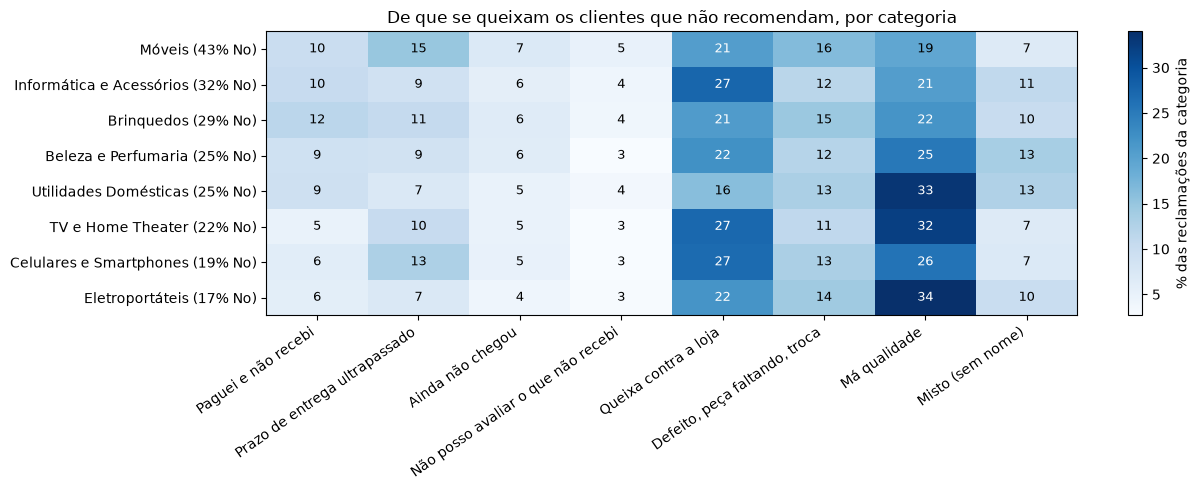

In [11]:
# [C03.11]
# 3) tema × categoria: nas 8 categorias com mais avaliações, de que se queixam os clientes
CAT8 = base["site_category_lv1"].value_counts().index[:8]
neg8 = base.loc[negativas.index]
neg8 = neg8[neg8["site_category_lv1"].isin(CAT8)]
cruz = pd.crosstab(neg8["site_category_lv1"], neg8["tema"], normalize="index") * 100
taxa_no = base[base["site_category_lv1"].isin(CAT8)].groupby("site_category_lv1")["classe"].apply(lambda s: (s == "No").mean() * 100)
ordem = ["Paguei e não recebi", "Prazo de entrega ultrapassado", "Ainda não chegou", "Não posso avaliar o que não recebi",
         "Queixa contra a loja", "Defeito, peça faltando, troca", "Má qualidade", "Misto (sem nome)"]
cruz = cruz.loc[taxa_no.sort_values(ascending=False).index, ordem]

print("Não recomendam, por categoria (%):")
print(taxa_no.sort_values(ascending=False).round(1))
print()
print(cruz.round(1))

fig, eixo = plt.subplots(figsize=(13, 5))
imagem = eixo.imshow(cruz.values, cmap="Blues", aspect="auto")
eixo.set_xticks(range(cruz.shape[1]), cruz.columns, rotation=35, ha="right")
eixo.set_yticks(range(cruz.shape[0]), [f"{c} ({taxa_no[c]:.0f}% No)" for c in cruz.index])
for (i, j), v in np.ndenumerate(cruz.values):
    eixo.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > cruz.values.max() * 0.6 else "black", fontsize=9)
plt.colorbar(imagem, label="% das reclamações da categoria")
eixo.set_title("De que se queixam os clientes que não recomendam, por categoria")
plt.tight_layout()
plt.show()

Cruzámos o tema das reclamações com as 8 categorias com mais avaliações. Cada linha soma 100%, e mostra de que se queixam os clientes que não recomendam naquela categoria. A categoria vem acompanhada da percentagem de "No".

Móveis é a categoria com mais clientes que não recomendam (43,3%) e é onde o prazo ultrapassado mais pesa (14,9% das reclamações, contra 7,2% em Eletroportáteis). Faz sentido, porque são produtos grandes, com entrega mais difícil. A má qualidade pesa mais em Eletroportáteis (34,0%), Utilidades Domésticas (33,2%) e TV e Home Theater (32,2%). A queixa contra a loja pesa mais em Informática e Acessórios (27,5%), TV e Home Theater (27,3%) e Celulares (26,9%), que são produtos caros em que muitas vendas são de lojas parceiras.

Este é o cruzamento tema × sentimento × categoria pedido no enunciado. O sentimento é a nossa classe, o tema vem do NMF e a categoria vem da base.

## Recomendações

In [12]:
# [C03.12]
def citar(indices, n=3, pesos=None, minimo_palavras=8):
    # n avaliações reais, ao acaso com a semente, com pelo menos 8 palavras e pouca repetição
    # se vierem os pesos do NMF, o sorteio é feito entre as 50 com mais peso no tema
    candidatas = base.loc[indices]
    ok = ((candidatas["review_text"].str.split().str.len() >= minimo_palavras) & (candidatas["variedade"] >= 0.6)).values
    if pesos is not None:
        pesos = pd.Series(np.asarray(pesos), index=candidatas.index)[ok]
        candidatas = candidatas.loc[pesos.sort_values(ascending=False).index[:50]]
    else:
        candidatas = candidatas[ok]
    for _, linha in candidatas.sample(n, random_state=SEED).iterrows():
        print(f"   - [{linha['overall_rating']} estrelas, {linha['site_category_lv1']}] {linha['review_text'][:200]}")

# Recomendação 1: a entrega é o maior assunto das reclamações e também dos elogios
entrega_neg = grupo_neg == "Entrega"
entrega_pos = base.loc[positivas.index, "tema"].isin(["Chegou antes do prazo", "Entrega rápida"])
print("Reclamações sobre entrega (temas 2, 3, 4 e 6):", entrega_neg.sum(), "de", len(negativas),
      "(", round(entrega_neg.mean() * 100, 1), "% )")
print("Elogios sobre entrega (antes do prazo + rápida):", entrega_pos.sum(), "de", len(positivas),
      "(", round(entrega_pos.mean() * 100, 1), "% )")
por_categoria = (pd.Series(entrega_neg.values, index=negativas.index)
                   .groupby(negativas["site_category_lv1"]).agg(["mean", "size"]))
por_categoria = por_categoria[por_categoria["size"] >= 500].sort_values("mean", ascending=False)
print()
print("Reclamações sobre entrega, por categoria (categorias com 500+ reclamações), %:")
print((por_categoria["mean"] * 100).round(1))
print()
print("Avaliações:")
citar(negativas.index, pesos=W_neg[:, 2])

Reclamações sobre entrega (temas 2, 3, 4 e 6): 9184 de 32862 ( 27.9 % )
Elogios sobre entrega (antes do prazo + rápida): 27948 de 93859 ( 29.8 % )

Reclamações sobre entrega, por categoria (categorias com 500+ reclamações), %:
site_category_lv1
Móveis                      36.8
Games                       32.9
Brinquedos                  32.5
Eletrodomésticos            31.3
Casa e Construção           29.5
Informática e Acessórios    29.0
Esporte e Lazer             28.8
Saúde                       28.3
Bebês                       28.3
Automotivo                  27.0
Beleza e Perfumaria         26.8
Celulares e Smartphones     26.7
Moda                        25.2
Utilidades Domésticas       24.7
TV e Home Theater           22.7
Cama, Mesa e Banho          22.5
Informática                 22.1
Áudio                       21.5
Eletroportáteis             19.9
Name: mean, dtype: float64

Avaliações:
   - [1 estrelas, Ferramentas e Jardim] Ainda não recebi o produto  comprado dia 09/04/1

Recomendação 1: Tratar a entrega como o principal assunto da marca, nas queixas e nos elogios.

Destinatário: Logística, com o marketing.

O número: 27,9% das reclamações (9.184 de 32.862) são sobre a entrega. Com a queixa contra a loja, que também fala muito de pedidos parados, passa de metade. Do outro lado, 29,8% dos elogios (27.948) são sobre a entrega, ou porque chegou antes do prazo ou porque foi rápida. A entrega é o que mais faz um cliente recomendar e também o que mais o faz não recomendar.

O que fazer: A logística deve começar pelas categorias em que a entrega pesa mais nas reclamações, que são Móveis (36,8%), Games (32,9%), Brinquedos (32,5%) e Eletrodomésticos (31,3%). Nos exemplos o cliente compara sempre a data prometida com a data real ("estimativa de entrega foi dia 09/05/18", "paguei frete pra chegar antes e nada"). Por isso, a medida certa para a logística é a percentagem de pedidos entregues dentro do prazo prometido. O marketing deve prometer prazos que a logística consiga cumprir. "Chegou antes do prazo" é o segundo maior tema dos elogios (16,5%), e um prazo prometido com folga transforma a mesma entrega de reclamação em elogio.

In [13]:
# [C03.13]
# Recomendação 2: o pedido de avaliação chega antes do produto
NAO_RECEBIDO = (r"\bnao (?:recebi|chegou|foi entregue|me foi entregue)\b|\bainda nao (?:recebi|chegou)\b"
                r"|\bnem (?:recebi|chegou)\b|\bposso avaliar\b|\bcomo (?:vou |posso )?avaliar\b")
nao_recebido = base["texto_sem_acentos"].str.contains(NAO_RECEBIDO, regex=True)
print("Avaliações que dizem que o produto não chegou:", nao_recebido.sum(), "(", round(nao_recebido.mean() * 100, 1), "% da base )")
print("   entre as 'No':", (nao_recebido & (base["classe"] == "No")).sum(),
      "(", round(nao_recebido[base["classe"] == "No"].mean() * 100, 1), "% das reclamações )")
print("   entre as 'Yes':", (nao_recebido & (base["classe"] == "Yes")).sum())
print("Média de estrelas destas avaliações:", round(base.loc[nao_recebido, "overall_rating"].mean(), 2),
      ", na base toda:", round(base["overall_rating"].mean(), 2))
print("Com 1 estrela (%):", round((base.loc[nao_recebido, "overall_rating"] == 1).mean() * 100, 1))
print("Produtos diferentes que receberam pelo menos uma:", base.loc[nao_recebido, "product_id"].nunique())

# quanto uma destas avaliações pesa na nota do produto: produtos com 5 a 20 avaliações
contagem = base.groupby("product_id")["overall_rating"].agg(["size", "mean"])
afetados = base.loc[nao_recebido, "product_id"].unique()
media_sem = base[~nao_recebido].groupby("product_id")["overall_rating"].mean()
pequenos = contagem[(contagem["size"].between(5, 20)) & contagem.index.isin(afetados)]
queda = (media_sem.reindex(pequenos.index) - pequenos["mean"])
print("Produtos com 5 a 20 avaliações atingidos:", len(pequenos),
      ", a nota média deles desce em média", round(queda.mean(), 2), "estrelas por causa destas avaliações")
print()
print("Avaliações:")
citar(base.index[nao_recebido])

Avaliações que dizem que o produto não chegou: 6528 ( 5.2 % da base )
   entre as 'No': 5702 ( 17.4 % das reclamações )
   entre as 'Yes': 826
Média de estrelas destas avaliações: 1.36 , na base toda: 3.53
Com 1 estrela (%): 81.4
Produtos diferentes que receberam pelo menos uma: 5095
Produtos com 5 a 20 avaliações atingidos: 1071 , a nota média deles desce em média 0.32 estrelas por causa destas avaliações

Avaliações:
   - [1 estrelas, Eletroportáteis] Como posso avaliar o produto se eu não recebi o mesmo Muito decepcionado com a amercicanas. com
   - [1 estrelas, TV e Home Theater] Não posso Avaliar uma coisa que ainda não recebi até hoje!
   - [1 estrelas, Áudio] Simplesmente meu produto não chegou estou espera 1 mês 10 dias e nada .


Recomendação 2: Só pedir a avaliação do produto depois de o produto ser entregue.

Destinatário: Marketing (CRM, quem envia o convite para avaliar) e as equipes de categoria, que cuidam das páginas de produto.

O número: 6.528 avaliações (5,2% da base) dizem que o produto não chegou. São 17,4% de todas as reclamações. Têm em média 1,36 estrelas, contra 3,53 na base toda, e 81,4% têm 1 estrela. Esta nota vai para a página do produto, mas o produto não tem culpa nenhuma. Estas avaliações atingem 5.095 produtos diferentes. Nos 1.071 produtos com 5 a 20 avaliações, a nota média desce em média 0,32 estrelas só por causa delas.

Os próprios clientes dizem isto: "Como posso avaliar o produto se eu não recebi o mesmo", "Não posso Avaliar uma coisa que ainda não recebi até hoje!". É o tema 6 das negativas, "Não posso avaliar o que não recebi".

O que fazer: Enviar o convite para avaliar só depois da confirmação da entrega. Se o pedido estiver atrasado, enviar antes uma pergunta sobre a entrega, separada da nota do produto. Assim a queixa da entrega vai para a logística e a nota do produto deixa de ser contaminada. Pensamos também que o formulário pode ter um mínimo de caracteres, pelas avaliações com texto repetido para encher que vimos nos temas-artefato. Isto não é medido diretamente, porque a base não traz as regras do formulário.

In [14]:
# [C03.14]
# Recomendação 3: problemas próprios de cada categoria (recorte 2 da secção 3.5)
NOMES_CAT = {
    "Celulares e Smartphones": {2: "Parou de funcionar com pouco uso", 5: "Bateria", 6: "Tela, câmera e travamentos"},
    "Eletroportáteis": {2: "Bebedouro e purificador não gelam", 4: "Cafeteira: café morno e pó"},
    "Beleza e Perfumaria": {2: "Perfume não original ou sem fixação", 3: "Chapinha e escova estragam o cabelo"},
}
for c, nomes in NOMES_CAT.items():
    dominante = temas_categoria[c][0]
    print("=====", c, ", reclamações:", len(dominante))
    for tema, nome in nomes.items():
        print(f"   {nome}: {(dominante == tema).sum()} ({(dominante == tema).mean() * 100:.1f}%)")
    juntos = dominante.isin(list(nomes))
    print(f"   juntos: {juntos.mean() * 100:.1f}% das reclamações da categoria")

print()
print("Avaliações (uma por categoria):")
for c, tema in [("Celulares e Smartphones", 2), ("Eletroportáteis", 2), ("Beleza e Perfumaria", 2)]:
    dominante, W, _ = temas_categoria[c]
    citar(dominante.index, n=1, pesos=W[:, tema - 1])

===== Celulares e Smartphones , reclamações: 3873
   Parou de funcionar com pouco uso: 749 (19.3%)
   Bateria: 438 (11.3%)
   Tela, câmera e travamentos: 705 (18.2%)
   juntos: 48.9% das reclamações da categoria
===== Eletroportáteis , reclamações: 1991
   Bebedouro e purificador não gelam: 260 (13.1%)
   Cafeteira: café morno e pó: 148 (7.4%)
   juntos: 20.5% das reclamações da categoria
===== Beleza e Perfumaria , reclamações: 2201
   Perfume não original ou sem fixação: 273 (12.4%)
   Chapinha e escova estragam o cabelo: 531 (24.1%)
   juntos: 36.5% das reclamações da categoria

Avaliações (uma por categoria):


   - [1 estrelas, Celulares e Smartphones] Aparelho Realmente Muito Bom Pelo Seu Desempenho. Porém Fiquei Muito Insatisfeito Por Conta Da Tela, Pois Não Existe No Mercado Película Que Se Adapte Bem Ao Aparelho. Principalmente Se Quisermos Usar
   - [2 estrelas, Eletroportáteis] Sai pouquíssima água, leva 2 minutos pra encher um copo pequeno. E nada tem a ver com a pressão da água, pois até a água gelada que vem do reservatório sai pouca. Até esperar acabar de encher o copo a
   - [1 estrelas, Beleza e Perfumaria] n  recomendo  esse  Perfume Silver Scent Masculino 100ml Jacques Bogart  o  cheiro  dele  e muito  enjoativo       ja  o  Perfume Ferrari Black 125ml tem  sua  duração muito  pouca  n  dura  nem  1  h


Recomendação 3: Corrigir a descrição dos produtos e verificar os fornecedores nos problemas próprios de cada categoria.

Destinatário: Equipes de categoria (compras e catálogo).

O número: No recorte por categoria da secção 3.5, os temas próprios de cada categoria são uma fatia grande das reclamações. Nos celulares, "parou de funcionar com pouco uso" (19,3%), "tela, câmera e travamentos" (18,2%) e "bateria" (11,3%) somam 48,9% das reclamações. Em Beleza e Perfumaria, "perfume não original ou sem fixação" tem 12,4% e a chapinha 24,1%. Nos eletroportáteis, "bebedouro e purificador não gelam" tem 13,1% e "cafeteira: café morno e pó" 7,4%.

O que fazer: Cada tema pede uma ação diferente.
- Perfume não original: Verificar a origem dos perfumes vendidos por lojas parceiras e pedir nota fiscal do importador. Uma suspeita de falsificação estraga a confiança na loja, e não só no produto ("Admiro muito um site conceituado como americanas vende um produto desse, este é falso").
- Bebedouros e cafeteiras: A queixa é sobre o que o cliente esperava ("só fica uma água fresca nada doque eu esperava", "sai pouquíssima água"). Pôr na página a temperatura real e a vazão, em vez de "água gelada".
- Celulares: Acompanhar por modelo as reclamações de "parou de funcionar com pouco uso" e de bateria, e deixar de vender os modelos ou fornecedores com mais queixas.

In [15]:
# [C03.15]
# Recomendação 4: quem reclama quer uma resposta
pos_venda = base.loc[negativas.index, "tema"].isin(["Defeito, peça faltando, troca", "Queixa contra a loja"])
print("Reclamações de defeito/troca e contra a loja:", pos_venda.sum(), "(", round(pos_venda.mean() * 100, 1), "% das reclamações )")

SEM_RESPOSTA = (r"\b(?:nao|nunca|ninguem|nem) (?:me )?(?:respond\w*|retorn\w*|resolv\w*)\b"
                r"|\b(?:nao|nem|nunca) (?:me )?(?:deram|da|dao|tive|tenho|obtive|recebi) (?:nenhum |nenhuma |qualquer )?(?:retorno|resposta|satisfacao|posicao)\b"
                r"|\bsem (?:nenhum |nenhuma |qualquer )?(?:resposta|retorno|satisfacao)\b|\bentrei em contato\b")
sem_resposta = base["texto_sem_acentos"].str.contains(SEM_RESPOSTA, regex=True)
print("Reclamações que dizem que tentaram contato ou não tiveram resposta:",
      sem_resposta[base["classe"] == "No"].sum(), "(", round(sem_resposta[base["classe"] == "No"].mean() * 100, 1), "% das reclamações )")
print("   nas avaliações 'Yes' (%):", round(sem_resposta[base["classe"] == "Yes"].mean() * 100, 1))
por_tema = base.loc[negativas.index].assign(sem_resposta=sem_resposta).groupby("tema")["sem_resposta"].mean() * 100
print()
print("Sem resposta, por tema das reclamações (%):")
print(por_tema.sort_values(ascending=False).round(1))
print()
print("Avaliações:")
citar(base.index[sem_resposta & (base["classe"] == "No")])

Reclamações de defeito/troca e contra a loja: 11983 ( 36.5 % das reclamações )


Reclamações que dizem que tentaram contato ou não tiveram resposta: 1925 ( 5.9 % das reclamações )
   nas avaliações 'Yes' (%): 0.3

Sem resposta, por tema das reclamações (%):
tema
Queixa contra a loja                  11.2
Paguei e não recebi                    8.7
Defeito, peça faltando, troca          7.8
Prazo de entrega ultrapassado          6.8
Ainda não chegou                       5.0
Não posso avaliar o que não recebi     2.5
Misto (sem nome)                       2.4
Má qualidade                           0.6
sem tema                               0.0
Name: sem_resposta, dtype: float64

Avaliações:
   - [1 estrelas, Brinquedos] O que achar de um produto que duas vezes comprei e tive que cancelar a compra.  1- Comprei em dezembro e não entregaram no prazo. Cancelei o pedido.  2- Comprei novamente o produto é me entregaram fal
   - [1 estrelas, Casa e Construção] Primeira vez que usei estourou... entrei em.contato com a Americanas para devolução e até agora ñ tive retorno. Est

Recomendação 4: Responder a quem reclama, sobretudo nas trocas e nas compras a lojas parceiras.

Destinatário: Atendimento ao cliente (SAC e pós-venda) e a gestão das lojas parceiras do marketplace.

O número: 36,5% das reclamações (11.983) são de defeito, peça faltando ou troca (tema 5) ou contra a loja (tema 7). São clientes que precisam de uma resposta. Medimos também as reclamações que dizem que tentaram contacto ou que não tiveram resposta ("não me respondem", "sem retorno", "entrei em contato"). São 1.925, ou seja 5,9% das reclamações, contra 0,3% nas avaliações positivas. A falta de resposta aparece mais na queixa contra a loja (11,2%), em "paguei e não recebi" (8,7%) e nas trocas (7,8%).

O que fazer: Usar o classificador do notebook 02 para encontrar estas avaliações e encaminhá-las para o atendimento. Para isto a versão balanceada do classificador é a mais indicada, porque apanha 90,7% das avaliações "No" (notebook 02, secção 3.4). Nas compras a lojas parceiras, o cliente nem sabe a quem se queixar ("Não sei se é problema da Americanas ou da loja"). O atendimento da Americanas deve ser o ponto de contacto também nessas compras, e as lojas parceiras devem ter um prazo de resposta.

## Limites

O que estes números não permitem concluir:

- A base é de 2018: As avaliações são de janeiro a maio de 2018. A logística, o marketplace e o formulário de avaliação podem ter mudado desde então. As percentagens descrevem aqueles cinco meses e não a Americanas de hoje.
- Só quem avaliou está na base: Não sabemos quantos clientes compraram sem avaliar. Quem tem um problema pode avaliar mais do que quem ficou satisfeito, ou o contrário. Por isso os 25,9% de "No" não são a taxa de clientes insatisfeitos. São a taxa entre quem escreveu.
- Não há preço: O "custo-benefício" aparece nos elogios, mas não sabemos o preço de nenhum produto. Não dá para dizer se os produtos baratos têm mais queixas de qualidade.
- Não há resposta da loja: A base não diz se a Americanas respondeu, nem como. A recomendação 4 vem do que o cliente escreveu, não do que o atendimento fez.
- Não há devolução registada: Os temas de defeito e troca dizem que o cliente pediu a troca, mas não sabemos quantas trocas aconteceram nem quantos produtos voltaram.
- Não sabemos quem vendeu: A base não separa a Americanas das lojas parceiras do marketplace. A "queixa contra a loja" junta as duas, e os próprios clientes também não sabem distinguir.
- Os temas são uma leitura nossa: O NMF devolve sempre k grupos. Os nomes são a nossa interpretação e outra equipe podia dar outros nomes ou escolher outro k. Cada avaliação ficou só com o seu tema principal, mas muitas falam de mais de um assunto, como produto bom e entrega atrasada. Um tema ficou sem nome (10,0% das reclamações) e dois temas positivos não têm assunto.
- As regras de texto são aproximadas: A contagem de "produto não recebido" e de "sem resposta" usa expressões regulares escritas pela equipe. Apanha as formas mais comuns e deixa escapar outras, por isso os números são um mínimo e não um valor exato.
- Correlação, não causa: Saber que Móveis tem mais queixas de prazo não prova que a entrega de móveis é pior. Pode ser que quem compra móveis tenha prazos mais longos ou avalie mais. As recomendações dizem onde olhar primeiro, não o que causa o problema.